The pass component estimates team completion probability at a candidate destination from the current player state. Its lineage is Spearman's **Physics-Based Modeling of Pass Probabilities in Soccer** and **Beyond Expected Goals** [@spearman2017; @spearman2018beyond]. PRESS uses two distinct calculations: a reconstructed-path likelihood for parameter estimation, and a potential pitch control field (PPCF) for inference. This vignette documents the implemented equations and executes both interfaces.

## Inputs and meaning

Positions are centred pitch metres, velocity is m/s, acceleration is m/s², and time is seconds after release. Player state is fixed at the evaluated frame. The carrier is excluded from potential receivers and from competing control mass. The output is team pass success; `1 - pass_success` is the pass-failure branch used by PRESS. Destination selection is a separate model.

## Reachability and uncertain arrival

Spearman combines an expected interception time with logistic temporal uncertainty [@spearman2017]. PRESS approximates reachability with a sequential change of direction, acceleration and cruise. For player position **p**, initial speed u, destination **r**, distance d and angle θ between velocity and destination:

$$
t_a=\max\{(v_{\max}-u)/a,0\},\qquad d_a=u t_a+\tfrac12 a t_a^2,
$$
$$
\tau_{\mathrm{move}}(d)=
\begin{cases}
(\sqrt{u^2+2ad}-u)/a,&d\le d_a,\\
t_a+(d-d_a)/v_{\max},&d>d_a.
\end{cases}
$$
$$
\tau_{\mathrm{turn}}=u\theta/a_{\mathrm{turn}},\qquad
\tau_j(\mathbf r)=\tau_{\mathrm{turn}}+\tau_{\mathrm{move}}.
$$

The turning term is a fixed-position delay approximation, not an explicit circular trajectory. At rest it is zero; within 0.1 m of the target the implementation sets arrival time to zero. The benchmark uses `a_turn=a=7` and its legacy cruise-at-cap convention when initial speed exceeds the cap. The low-level TTI helper also exposes `a_turn` and `preserve_initial_overspeed` for sensitivities. These sequential-motion choices are **PRESS implementation assumptions**, rather than a claim to reproduce every detail of Spearman's optimizer.

The arrival gate is

$$
F_j(t,\mathbf r)=\operatorname{sigmoid}\!\left[
\frac{\pi\{t-\tau_j(\mathbf r)\}}{\sqrt3\,s}\right].
$$

Here s is the logistic standard deviation in seconds; the logistic scale is √3s/π. At the expected arrival time, F is 0.5. It represents uncertain reachability, not a normalized distribution over players. Variability in facing direction, awareness, effort and tracking accuracy is absorbed in this arrival dispersion and the control model.

### Why a 5.5 m/s cap?

The selected cap is an effective interception speed, rather than a player's maximum sprint speed. It is motivated by the upper tail of off-ball speeds after excluding the operational walking band, **speed ≤2 m/s**. Recomputed on the current ten-match tracking, the pooled 95th percentile is **5.745 m/s** over 3,865,755 eligible player-frame observations: the annotated carrier is removed and frames with no carrier annotation are retained. Under the historical script's narrower selection of frames with no annotated carrier, the percentile is **5.656 m/s**. Therefore **5.5 m/s is a nearby empirical threshold**, not an exact measured 95th percentile. It also improved the held-out results relative to 5 m/s in the tested sensitivity. [Quantile summary](../../data/benchmarks/pass_risk/offball_speed_summary.json), [per-match statistics](../../data/benchmarks/pass_risk/offball_speed_by_match.csv).

The acceleration setting **7 m/s²** follows the value used in *Beyond Expected Goals*, whose reference effective speed is 5 m/s [@spearman2018beyond]. Shared values describe average capabilities; individual caps remain an extension.

## Ball flight

Following the constant-drag flight formulation of Spearman 2017, the airborne ball obeys

$$
\dot{\mathbf R}=\mathbf V,\qquad
\dot{\mathbf V}=-g\mathbf e_z-
\frac{\rho C_D A}{2m}\|\mathbf V\|\mathbf V.
$$

The benchmark uses ρ=1.22 kg/m³, C_D=0.25, A=0.038 m², m=0.42 kg and g=9.81 m/s². Spin and Magnus force are unobserved and omitted, so horizontal flight is straight. Spearman also discusses the resulting limitation [@spearman2017]. The ODE is integrated numerically; its solver is distinct from the exponential-Euler control update below.

The implemented ground approximation holds height once the descending ball is below 5 cm and continues horizontal aerodynamic drag. There is no bounce or fitted rolling friction. The latent vertical-velocity state is held rather than reset and is not interpreted as physical post-impact velocity; downstream calculations use position and height.

### Reconstructed passes for estimation

Release position is observed. Two boundary estimators were compared: mean velocity in five initial frames, and a least-squares fit of launch speed, elevation and horizontal direction to five ball positions. These positions are sampled at **0, 0.1, 0.2, 0.3, 0.4 s**. The fit fixes release position, constrains launch speed to 1–40 m/s and elevation to 0–60°, and estimates direction; the annotated target initializes direction but is not an endpoint fitting constraint. Numerical failure has an explicit fallback to the mean boundary.

Each boundary projects a 3D path to 10 s at 0.04 s spacing. The method is selected using only fitting matches, by equal-match-weight mean forecast error after 0.6 s and before the next control. All outer fits and the full-data refit selected **fit_positions**. Centred velocity smoothing can use observations through 0.6 s; the 0.5 s minimum protects the five-position window, rather than making the historical mean-velocity alternative strictly causal. These are offline parameter-estimation procedures.

### Hypothetical passes for inference

At each candidate target, PRESS simulates 900 launch combinations: 30 speeds from 5–25 m/s and 30 elevations from 0–45°. Among reachable candidates at controllable height, it selects the flight time closest to the TTI of the teammate **nearest in initial position to that target**, excluding the carrier. This is the receiver-friendly timing assumption of *Beyond Expected Goals*, §3.1.2 [@spearman2018beyond]. The computation uses the exact target distance; the corrected radial lookup is an optional approximation.

This field treats interception near the destination as a proxy for blocked passes. It does not integrate each hypothetical pass along its whole route. The assumption can be useful for lofted passes but remains a simplification for ground passes and early blocks.

## Competing control probabilities

Let P_j(t) be the probability that player j has controlled the ball and U(t)=1−Σ_j P_j(t) the remaining uncontrolled probability. The control equation combines arrival with a control rate, as in Spearman's models:

$$
\frac{dP_j}{dt}=U(t)h_j(t),\qquad h_j(t)=\lambda_{\mathrm{control}}F_j(t)G(t),
\qquad P_j(0)=0.
$$

λ_control has units s⁻¹ and is shared by both teams here. The control condition G distinguishes the two uses:

- **Reconstructed-path likelihood:** evaluate F at the moving ball's XY position; G is one when ball height is at most 2 m.
- **Target PPCF:** evaluate F at the fixed destination; G is one after its selected ball-arrival time. The attacking probability is the sum over teammates excluding the passer.

The shared U makes the players compete for the same ball. Each step freezes the rates, sets H=Σ_j h_j, and uses the mass-preserving update

$$
\Delta P_j=U\{1-\exp(-H\Delta t)\}\frac{h_j}{H},\qquad
U_{\mathrm{next}}=U\exp(-H\Delta t),
$$

with zero increment for H=0. This exponential Euler update preserves total probability at most one for nonnegative rates; it is first order when rates vary over time. The schedule has no parameter-dependent early stopping. Candidate PPCF uses 0.01 s steps to 15 s. The reconstructed-path benchmark retains its historical left-step convention: 251 positions at 0..10 s start 251 intervals of 0.04 s, giving a 10.04 s control schedule.

## Parameter fitting and calibration

λ_control and s are estimated by **maximum likelihood**, without priors, using reconstructed-path success probabilities and natural binary outcomes. Positive parameters are represented in logarithmic coordinates. Three initializations check the optimum; stable log-probabilities avoid a fitting-time probability floor.

The fitted parameters are transferred to the hypothetical target PPCF. Its raw score is calibrated by an increasing isotonic function fitted only to match-held-out PPCF scores. The benchmark uses nested 6-fit + 2-calibration-prediction + 2-test match rotations; the deployed model refits physical parameters on all ten matches and its final isotonic map on outer cross-fitted raw scores. Loading the artifact never trains a model. [Full protocol and results](../../benchmark.qmd#pass-risk-benchmark).

The accepted artifact has **λ_control=5.206773 s⁻¹, s=0.330402 s, v_max=5.5 m/s, a=7 m/s²**. These are full-data operational estimates; performance comes from separate pooled outer predictions.

## Executable physical-path example

The following synthetic example generates a gravity-and-drag trajectory and evaluates attacking control along it with the installed parameters. It illustrates the estimation primitive; it is not the calibrated PPCF or a match benchmark.


Installed model: skillcorner_outfield_pass_risk_duration_v3
lambda_control: 5.206773021540777 s: 0.3304016005107726


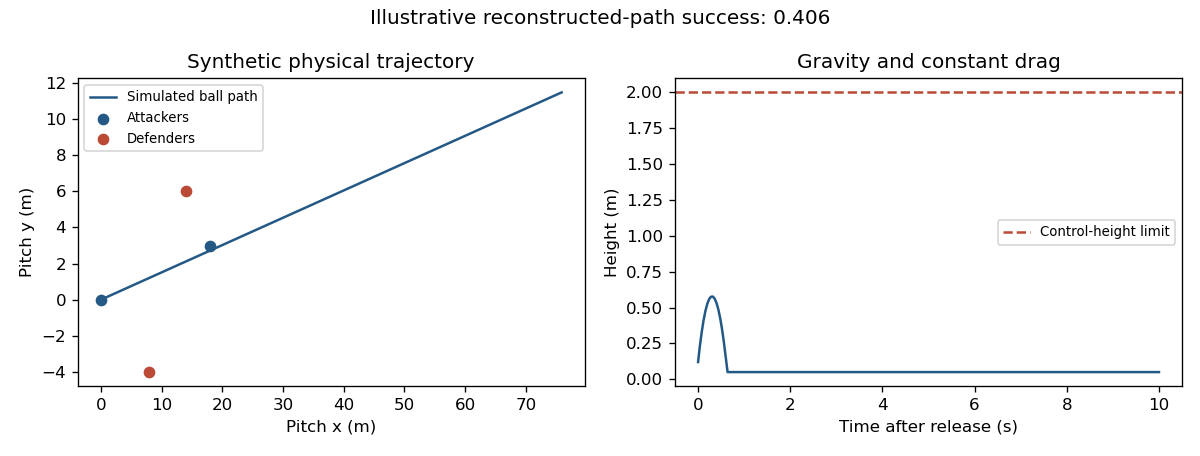

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import jax
jax.config.update("jax_enable_x64", True)
from PRESS.model import PassRiskModel
from PRESS.physics.flight_ball import ball_trajectory
from PRESS.model.solver_pitch_control import integrate_pass_prob

fitted = PassRiskModel.pretrained()
physics = fitted.physics
t = np.arange(251) * 0.04
flight = np.asarray(ball_trajectory(14., 0.22, t, z0=0.12,
    **{k: physics[k] for k in ("rho", "Cd", "A", "m", "g")}))
phi = 0.15
ball = np.column_stack([flight[:, 0]*np.cos(phi), flight[:, 0]*np.sin(phi), flight[:, 1]])
pos = np.array([[0.,0.], [18.,3.], [8.,-4.], [14.,6.]])
vel = np.zeros_like(pos)
prob = integrate_pass_prob(pos, vel, np.array([0,1]), 0, ball,
    lambda_control=fitted.lambda_control, s=fitted.s, v_max=physics["v_max"],
    a_max=physics["a_max"], dt=0.04, z_max=physics["z_max"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(ball[:,0], ball[:,1], color="#245985", label="Simulated ball path")
axes[0].scatter(pos[:2,0], pos[:2,1], color="#245985", label="Attackers")
axes[0].scatter(pos[2:,0], pos[2:,1], color="#ba4a36", label="Defenders")
axes[0].set(xlabel="Pitch x (m)", ylabel="Pitch y (m)", title="Synthetic physical trajectory")
axes[0].legend(fontsize=8)
axes[1].plot(t, ball[:,2], color="#245985")
axes[1].axhline(physics["z_max"], color="#ba4a36", ls="--", label="Control-height limit")
axes[1].set(xlabel="Time after release (s)", ylabel="Height (m)", title="Gravity and constant drag")
axes[1].legend(fontsize=8)
fig.suptitle(f"Illustrative reconstructed-path success: {float(prob):.3f}")
fig.tight_layout()
out = Path("figures/vignette_02_pass_probability.png"); out.parent.mkdir(exist_ok=True)
fig.savefig(out, dpi=150); fig.savefig(out.with_suffix(".svg"))
print("Installed model:", fitted.model_id)
print("lambda_control:", fitted.lambda_control, "s:", fitted.s)


## Use the installed model at any usable frame

This example initializes a synthetic match, selects a possession and frame 5 inside an action interval, computes candidate PPCF and plots calibrated pass success using the package pitch visualization. Segmentation does not restrict which usable frames can be evaluated. The coarse grid is for a quick demonstration; changing it changes the candidate set.

`PassRiskModel.pretrained()` loads learned parameters and the isotonic map. `PRESS` also loads that model by default when `compute_ppcf` is called. For local processed data, use `PRESS.from_skillcorner(...)` as described in the [match guide](../../usage.qmd). Physics overrides are sensitivities; their outputs are not covered by the saved calibration assessment.


Frame: 5 candidate grid: (117, 2)
Pass-success range: 0.057971014492753624 1.0
Calibration: isotonic


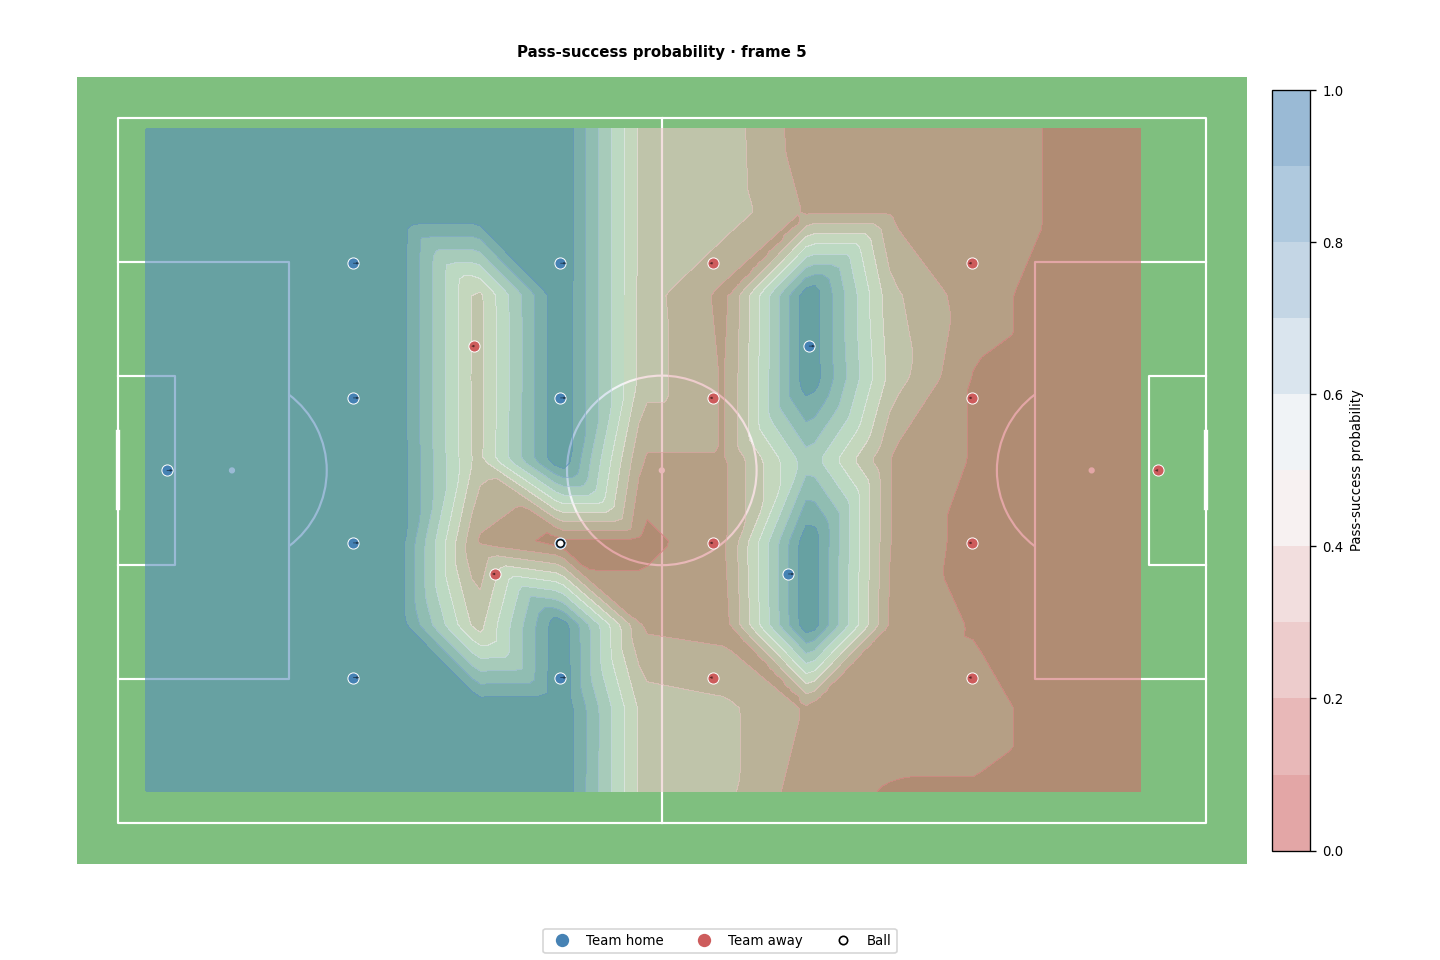

In [5]:
from PRESS import PRESS
from PRESS.datasets import load_demo_match
from PRESS.visualization import plot_ppcf

tracking, possessions, actions, xT_grid = load_demo_match()
model = PRESS(tracking, possessions_data=possessions, actions_data=actions,
              pass_risk_model=fitted)
possession_id = model.get_possessions().possession_id.iloc[0]
frame_id = int(model.get_frames(possession_id, valid_only=True).frame.iloc[5])
model.compute_ppcf(frame_id, r_max=80, step=8)
result = model.get_ppcf_result(frame_id)
print("Frame:", frame_id, "candidate grid:", np.asarray(result["grid"]).shape)
print("Pass-success range:", float(np.min(result["Pass probability"])),
      float(np.max(result["Pass probability"])))
print("Calibration:", result["params"]["calibration"])
assert result["params"]["calibration_matches_physics"]
plot_ppcf(model, frame_id, field="pass_success")
fig = plt.gcf()
out = Path("figures/vignette_02_pass_pitch.png")
fig.savefig(out, dpi=150); fig.savefig(out.with_suffix(".svg"))


## Benchmark and limits

The accepted training cohort contains **6,706 passes, 964 failures**, with matched continuous endpoints, outfield passers and flight duration **[0.5, 10] s**. All valid curvature levels are retained. Nested held-out match evaluation gives **CE 0.141912, gain over the training-fold null 65.57%, ECE at ten quantile bins 0.353%**. These are development OOF results; the ten matches also informed model choices.

The same all-pass-trained model and calibrator give CE **0.107061** on curvature <10% and **0.263390** on curvature ≥10%; subgroup-relative gains are **71.41%** and **49.46%**, respectively. This is consistent with room to improve the simplified flight model and its boundary conditions. It does not isolate spin as the cause: pass geometry, difficulty, label prevalence and tracking quality also differ. Curvature is retrospective and is not an inference-time feature or a training filter. [Results, comparison and calibration figure](../../benchmark.qmd#pass-risk-benchmark).

Additional limits are the receiver-friendly timing assumption, early blocks represented through destination control, shared average player capabilities, the recovery-point proxy for failed-pass intent, centred smoothing and limited match count. Shorter passes with an adapted initial-condition estimator remain an extension.

## References

- [Spearman et al. (2017), *Physics-Based Modeling of Pass Probabilities in Soccer*](https://static.hudl.com/craft/downloads/SSAC17-Physics-Based-Modeling-of-Pass-Probabilities-in-Soccer.pdf): trajectory/control likelihood and simplified flight. [@spearman2017]
- [Spearman (2018), *Beyond Expected Goals*](https://static.hudl.com/craft/downloads/SSAC2018_Beyond_Expected_Goals.pdf): potential pitch control, arrival-time matching and its behavioural assumptions. [@spearman2018beyond]
- [Fernández, Bornn and Cervone (2021)](https://arxiv.org/abs/2011.09426): pass-success component and calibrated EPV framework. [@fernandez2021]
- [Stalpaert (2022), *CounterRisk*](https://belgianfootball.s3.eu-central-1.amazonaws.com/s3fs-public/rbfa/docs/pdf/rbfa_knowledge_centre/studies/RBFA_Study_30_Counter_Risk.pdf): tree-model comparison. [@stalpaert2022]
